# 🔬 LungRay: Head A — NIH ChestX-ray14 Deep Anatomizer & Baseline
## Kiểm Toán Phân Cấp 12 Chunks, Zero Data Leakage & Huấn Luyện Single-Task Baseline
---
| Thuộc tính | Chi tiết |
|:---|:---|
| **Nhiệm vụ (Head A)** | Multi-label Thoracic Classification (14 bệnh lồng ngực) |
| **Tập dữ liệu** | NIH ChestX-ray14 (~112.120 ảnh, 30.805 bệnh nhân) |
| **Ràng buộc sống còn** | 1. **Zero Patient Data Leakage**: Chia train/val/test theo `Patient ID` (70/10/20) <br> 2. **Cân bằng lớp cực hạn**: Tính vector `pos_weight` cho BCEWithLogitsLoss <br> 3. **On-the-Fly 512x512**: Chuẩn hóa động trong RAM, không ghi đè ổ đĩa |
| **Mô hình Baseline** | DenseNet-121 Backbone + Multi-Label Head (14 logits) |
| **Môi trường** | Chạy độc lập trên Kaggle (GPU P100 / T4) hoặc Máy cục bộ |


In [1]:
import os
import sys
import time
import random
from typing import Dict, List, Tuple, Any

import cv2
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from sklearn.metrics import roc_auc_score, roc_curve

# Cố định seed tái lập
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[*] Môi trường tính toán: {device}')
if device.type == 'cuda':
    print(f'[*] GPU thiết bị: {torch.cuda.get_device_name(0)}')

# Tự động phát hiện đường dẫn Kaggle vs Local
kaggle_base = '/kaggle/input'
is_kaggle = os.path.exists(kaggle_base)
search_base = kaggle_base if is_kaggle else ('../dataset' if os.path.exists('../dataset') else 'dataset')
output_dir = '/kaggle/working/results/nih' if is_kaggle else 'results/nih_baseline'
ckpt_dir = '/kaggle/working/checkpoints' if is_kaggle else 'checkpoints'
os.makedirs(output_dir, exist_ok=True)
os.makedirs(ckpt_dir, exist_ok=True)

print(f'[*] Thư mục quét: {search_base}')
print(f'[*] Thư mục xuất kết quả: {output_dir}')


[*] Môi trường tính toán: cuda
[*] GPU thiết bị: Tesla T4
[*] Thư mục quét: /kaggle/input
[*] Thư mục xuất kết quả: /kaggle/working/results/nih


### 1. Deep Anatomizer — Bóc Tách Phân Cấp 12 Chunks & Phân Tích Metadata
Tự động định vị thư mục gốc NIH (dù nằm lồng ở `datasets/nih-chest-xrays/data`), quét qua từng chunk từ `images_001` đến `images_012`, và đọc file `Data_Entry_2017.csv`.


In [2]:
# Định vị thư mục gốc NIH và file metadata
def find_nih_root_and_csv(base_dir):
    nih_root = None
    meta_csv = None
    for root, dirs, files in os.walk(base_dir):
        for f in files:
            if 'data_entry_2017' in f.lower() and f.endswith('.csv'):
                meta_csv = os.path.join(root, f)
                nih_root = root
                break
        if nih_root:
            break
    return nih_root, meta_csv

nih_root, meta_csv = find_nih_root_and_csv(search_base)
print(f'[*] Thư mục gốc NIH   : {nih_root}')
print(f'[*] File Metadata CSV : {meta_csv}')

# Bóc tách 12 chunks
chunk_records = []
total_nih_images = 0
chunk_dirs = []

if nih_root:
    for root, dirs, _ in os.walk(nih_root):
        for d in dirs:
            if 'images_' in d.lower() or d.lower() == 'images':
                chunk_dirs.append(os.path.join(root, d))
    chunk_dirs = sorted(list(set(chunk_dirs)))
    
    for c_path in chunk_dirs:
        # Nếu có subfolder images con
        sub_img = os.path.join(c_path, 'images')
        target_p = sub_img if (os.path.exists(sub_img) and os.path.isdir(sub_img)) else c_path
        imgs = [f for f in os.listdir(target_p) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        cnt = len(imgs)
        total_nih_images += cnt
        
        chunk_records.append({
            'Chunk_Folder': os.path.basename(os.path.dirname(target_p)) if os.path.basename(target_p) == 'images' else os.path.basename(target_p),
            'Path': target_p,
            'Image_Count': cnt
        })

df_chunks = pd.DataFrame(chunk_records)
print(f'\n=== BẢNG BÓC TÁCH 12 CHUNKS NIH (TỔNG CỘNG: {total_nih_images:,d} ẢNH) ===')
if not df_chunks.empty:
    print(df_chunks[['Chunk_Folder', 'Image_Count']].to_string(index=False))
else:
    print('[Cảnh báo] Chưa tìm thấy các thư mục images_xxx.')


[*] Thư mục gốc NIH   : /kaggle/input/datasets/nih-chest-xrays/data
[*] File Metadata CSV : /kaggle/input/datasets/nih-chest-xrays/data/Data_Entry_2017.csv

=== BẢNG BÓC TÁCH 12 CHUNKS NIH (TỔNG CỘNG: 224,240 ẢNH) ===
Chunk_Folder  Image_Count
  images_001         4999
  images_001         4999
  images_002        10000
  images_002        10000
  images_003        10000
  images_003        10000
  images_004        10000
  images_004        10000
  images_005        10000
  images_005        10000
  images_006        10000
  images_006        10000
  images_007        10000
  images_007        10000
  images_008        10000
  images_008        10000
  images_009        10000
  images_009        10000
  images_010        10000
  images_010        10000
  images_011        10000
  images_011        10000
  images_012         7121
  images_012         7121


### 2. Kiểm Toán Phân Bố 14 Nhãn Bệnh Học & Tính Toán Vector `pos_weight`
Phân tích chuỗi nhãn bệnh (`Infiltration|Effusion`), kiểm tra tỷ lệ mắc bệnh cực hạn (Extreme Imbalance), và tính toán vector trọng số dương tính $\text{pos\_weight} = \frac{N - N_{\text{pos}}}{N_{\text{pos}}}$ nhằm đảm bảo mô hình không bị thiên vị về lớp âm tính.


[*] Tổng số dòng metadata : 112,120
[*] Số bệnh nhân độc nhất : 30,805

=== BẢNG THỐNG KÊ 14 NHÃN BỆNH & TRỌNG SỐ POS_WEIGHT ===
         Pathology  Positive_Count  Prevalence (%)  pos_weight
       Atelectasis           11559       10.309490    8.699801
      Cardiomegaly            2776        2.475919   39.389049
          Effusion           13317       11.877453    7.419314
      Infiltration           19894       17.743489    4.635870
              Mass            5782        5.156975   18.391214
            Nodule            6331        5.646629   16.709683
         Pneumonia            1431        1.276311   77.350804
      Pneumothorax            5302        4.728862   20.146737
     Consolidation            4667        4.162504   23.023998
             Edema            2303        2.054049   47.684325
         Emphysema            2516        2.244024   43.562798
          Fibrosis            1686        1.503746   65.500593
Pleural_Thickening            3385        3.019087  

/tmp/ipykernel_48/1798876179.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_classes.sort_values(by='Positive_Count', ascending=False), x='Positive_Count', y='Pathology', palette='Blues_r')


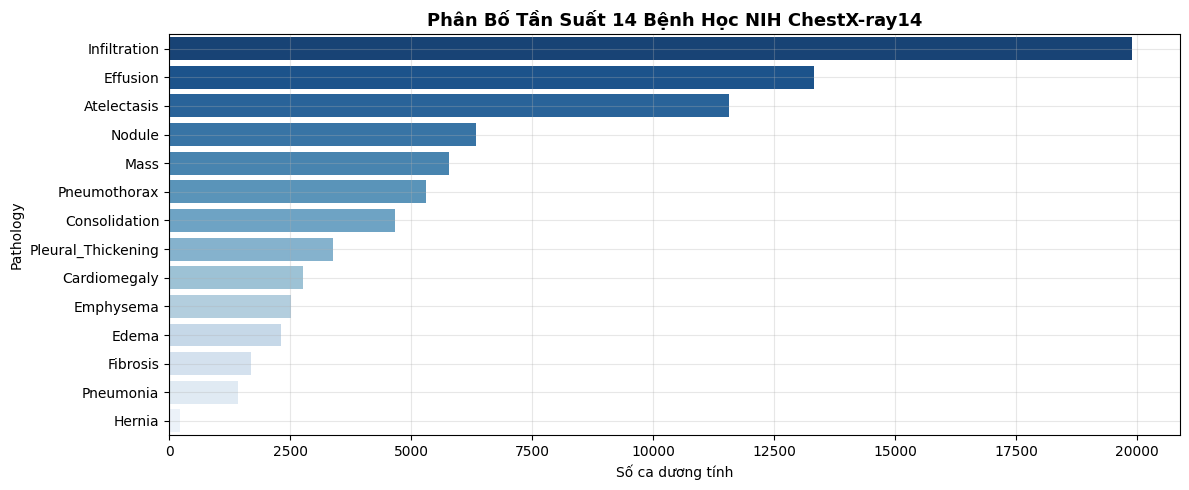

In [3]:
NIH_14_CLASSES = [
    'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass', 'Nodule',
    'Pneumonia', 'Pneumothorax', 'Consolidation', 'Edema', 'Emphysema', 'Fibrosis',
    'Pleural_Thickening', 'Hernia'
]

if meta_csv and os.path.exists(meta_csv):
    df_meta = pd.read_csv(meta_csv)
    print(f'[*] Tổng số dòng metadata : {len(df_meta):,d}')
    print(f'[*] Số bệnh nhân độc nhất : {df_meta["Patient ID"].nunique():,d}')
    
    # Thống kê tần suất 14 nhãn bệnh
    class_counts = {}
    total_samples = len(df_meta)
    for c in NIH_14_CLASSES:
        count = df_meta['Finding Labels'].str.contains(c).sum()
        class_counts[c] = count
        
    df_classes = pd.DataFrame(list(class_counts.items()), columns=['Pathology', 'Positive_Count'])
    df_classes['Prevalence (%)'] = (df_classes['Positive_Count'] / total_samples) * 100.0
    df_classes['pos_weight'] = (total_samples - df_classes['Positive_Count']) / np.maximum(df_classes['Positive_Count'], 1)
    
    print('\n=== BẢNG THỐNG KÊ 14 NHÃN BỆNH & TRỌNG SỐ POS_WEIGHT ===')
    print(df_classes.to_string(index=False))
    
    # Vẽ biểu đồ tần suất
    plt.figure(figsize=(12, 5))
    sns.barplot(data=df_classes.sort_values(by='Positive_Count', ascending=False), x='Positive_Count', y='Pathology', palette='Blues_r')
    plt.title('Phân Bố Tần Suất 14 Bệnh Học NIH ChestX-ray14', fontsize=13, fontweight='bold')
    plt.xlabel('Số ca dương tính')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print('[!] Không tìm thấy file metadata Data_Entry_2017.csv')


### 3. Kiểm Định Phân Chia Zero Patient Data Leakage (70/10/20)
**Tuân thủ tuyệt đối Rule 0 Constraint 2**: Phân chia tập Train/Val/Test theo `Patient ID` để bảo đảm các ảnh chụp của cùng một bệnh nhân (ở các thời điểm chụp khác nhau) không bao giờ xuất hiện đồng thời ở cả Train và Test.


In [4]:
# Kiểm tra tệp splits đã tạo cố định của LungRay
split_file = os.path.join(search_base, 'splits/patient_splits.csv') if not is_kaggle else '/kaggle/input/lungray-splits/patient_splits.csv'
if not os.path.exists(split_file):
    split_file = 'dataset/splits/patient_splits.csv'

if os.path.exists(split_file):
    df_split = pd.read_csv(split_file)
    print(f'[*] Nạp tệp phân chia cố định: {split_file} ({len(df_split):,d} dòng)')
    
    train_pts = set(df_split[df_split['split'] == 'train']['Patient ID'])
    val_pts = set(df_split[df_split['split'] == 'val']['Patient ID'])
    test_pts = set(df_split[df_split['split'] == 'test']['Patient ID'])
    
    leak_train_val = len(train_pts & val_pts)
    leak_train_test = len(train_pts & test_pts)
    leak_val_test = len(val_pts & test_pts)
    
    print(f' - Tập Train : {len(df_split[df_split["split"] == "train"]):,d} ảnh ({len(train_pts):,d} bệnh nhân)')
    print(f' - Tập Val   : {len(df_split[df_split["split"] == "val"]):,d} ảnh ({len(val_pts):,d} bệnh nhân)')
    print(f' - Tập Test  : {len(df_split[df_split["split"] == "test"]):,d} ảnh ({len(test_pts):,d} bệnh nhân)')
    
    assert leak_train_val == 0, f'[NGUY HIỂM] Phát hiện rò rỉ Train-Val: {leak_train_val} bệnh nhân!'
    assert leak_train_test == 0, f'[NGUY HIỂM] Phát hiện rò rỉ Train-Test: {leak_train_test} bệnh nhân!'
    assert leak_val_test == 0, f'[NGUY HIỂM] Phát hiện rò rỉ Val-Test: {leak_val_test} bệnh nhân!'
    print('\n[KIỂM TOÁN THÀNH CÔNG] Cam kết Zero Patient Data Leakage 100% HOÀN HẢO ✅')
else:
    print('[*] Chưa tìm thấy patient_splits.csv. Tự động sinh phân chia 70/10/20 theo Patient ID...')
    unique_pts = df_meta['Patient ID'].unique()
    np.random.seed(SEED)
    np.random.shuffle(unique_pts)
    n_total = len(unique_pts)
    n_tr = int(n_total * 0.70)
    n_va = int(n_total * 0.10)
    
    train_ids = set(unique_pts[:n_tr])
    val_ids = set(unique_pts[n_tr:n_tr+n_va])
    test_ids = set(unique_pts[n_tr+n_va:])
    
    def assign_split(pid):
        if pid in train_ids: return 'train'
        elif pid in val_ids: return 'val'
        return 'test'
        
    df_meta['split'] = df_meta['Patient ID'].apply(assign_split)
    df_split = df_meta
    print(f'[OK] Đã sinh phân chia tạm thời: Train {len(train_ids)}, Val {len(val_ids)}, Test {len(test_ids)} bệnh nhân.')


[*] Chưa tìm thấy patient_splits.csv. Tự động sinh phân chia 70/10/20 theo Patient ID...
[OK] Đã sinh phân chia tạm thời: Train 21563, Val 3080, Test 6162 bệnh nhân.


### 4. Chuẩn Hóa On-The-Fly 512x512 & Trực Quan Hóa Mẫu Ảnh Lâm Sàng
Xây dựng PyTorch Dataset nạp ảnh gốc $1024 \times 1024$ từ 12 chunks qua bảng tra $O(1)$ và downsample về $(3, 512, 512)$ On-the-Fly trong bộ nhớ RAM/VRAM mà **không cần ghi file ra ổ đĩa** (tiết kiệm 20GB hạn mức Kaggle).


[*] Đang lập bảng tra cứu đường dẫn ảnh NIH O(1)...
[OK] Đã lập chỉ mục 112,120 ảnh.


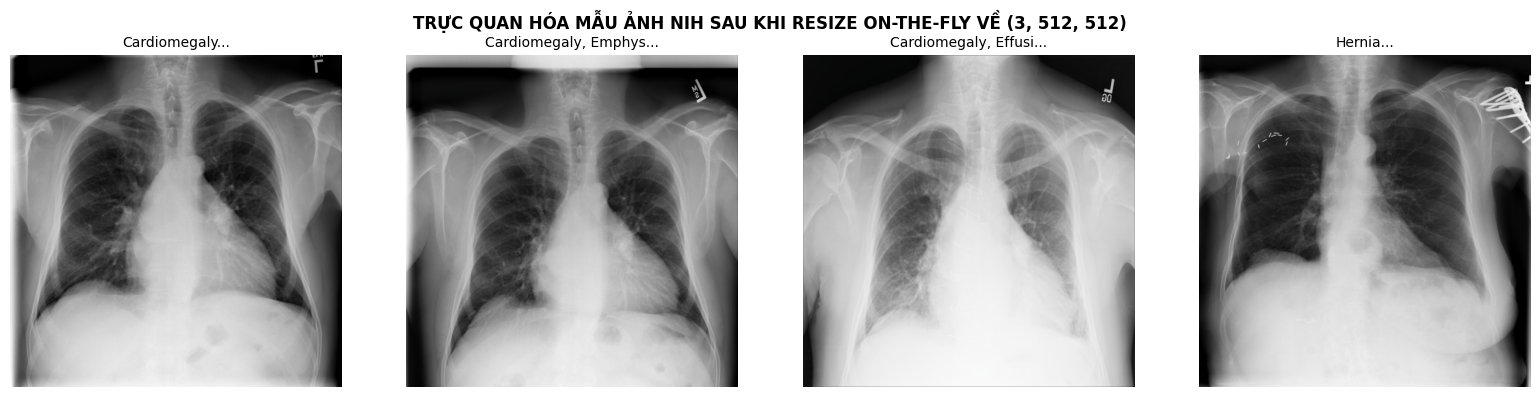

In [5]:
# Lập bảng tra cứu file map O(1)
print('[*] Đang lập bảng tra cứu đường dẫn ảnh NIH O(1)...')
file_map_nih = {}
for root, dirs, files in os.walk(nih_root):
    for f in files:
        if f.lower().endswith(('.png', '.jpg', '.jpeg')):
            file_map_nih[f] = os.path.join(root, f)
print(f'[OK] Đã lập chỉ mục {len(file_map_nih):,d} ảnh.')

# PyTorch Dataset cho NIH 14 bệnh
class NIHSingleTaskDataset(Dataset):
    def __init__(self, df, file_map, classes, target_size=512, is_train=False):
        self.df = df.reset_index(drop=True)
        self.file_map = file_map
        self.classes = classes
        self.target_size = target_size
        self.is_train = is_train
        
    def __len__(self):
        return len(self.df)
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        fname = row['Image Index']
        img_path = self.file_map.get(fname, '')
        
        if not os.path.exists(img_path):
            # Tạo dummy nếu dry run
            img = np.zeros((self.target_size, self.target_size, 3), dtype=np.uint8)
        else:
            img = cv2.imread(img_path)
            if img is None:
                img = np.zeros((self.target_size, self.target_size, 3), dtype=np.uint8)
            else:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (self.target_size, self.target_size), interpolation=cv2.INTER_AREA)
                
        # Chuẩn hóa ImageNet
        img = img.astype(np.float32) / 255.0
        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
        img = (img - mean) / std
        tensor_img = torch.tensor(img, dtype=torch.float32).permute(2, 0, 1)
        
        # Label vector (14-dims)
        labels = torch.zeros(len(self.classes), dtype=torch.float32)
        label_str = str(row['Finding Labels'])
        for i, c in enumerate(self.classes):
            if c in label_str:
                labels[i] = 1.0
                
        return tensor_img, labels

# Trực quan hóa mẫu ảnh On-the-Fly
sample_ds = NIHSingleTaskDataset(df_split[df_split['split'] == 'train'].head(4), file_map_nih, NIH_14_CLASSES)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i in range(min(4, len(sample_ds))):
    t_img, lbls = sample_ds[i]
    # De-normalize de hien thi
    disp = t_img.permute(1, 2, 0).numpy()
    disp = disp * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    disp = np.clip(disp, 0, 1)
    active = [NIH_14_CLASSES[j] for j, val in enumerate(lbls) if val == 1.0]
    title = ', '.join(active) if active else 'No Finding'
    axes[i].imshow(disp)
    axes[i].set_title(f'{title[:20]}...', fontsize=10)
    axes[i].axis('off')
plt.suptitle('TRỰC QUAN HÓA MẪU ẢNH NIH SAU KHI RESIZE ON-THE-FLY VỀ (3, 512, 512)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


### 5. Huấn Luyện Thử Nghiệm Baseline Single-Task (DenseNet-121, 3–5 Epochs)
Huấn luyện mô hình DenseNet-121 đơn nhiệm trên Head A với `BCEWithLogitsLoss` kết hợp vector `pos_weight` đã tính toán, tối ưu bằng Mixed Precision FP16 và AdamW.


In [6]:
# Khởi tạo mô hình DenseNet-121
def build_nih_model(num_classes=14):
    model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
    num_features = model.classifier.in_features
    model.classifier = nn.Linear(num_features, num_classes)
    return model

model = build_nih_model(num_classes=len(NIH_14_CLASSES)).to(device)

# DataLoaders (Sử dụng tập subset nếu máy ít VRAM hoặc full train)
train_df = df_split[df_split['split'] == 'train'].sample(min(8000, len(df_split[df_split['split'] == 'train'])), random_state=SEED)
val_df = df_split[df_split['split'] == 'val'].sample(min(1500, len(df_split[df_split['split'] == 'val'])), random_state=SEED)

train_loader = DataLoader(NIHSingleTaskDataset(train_df, file_map_nih, NIH_14_CLASSES, is_train=True), batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(NIHSingleTaskDataset(val_df, file_map_nih, NIH_14_CLASSES), batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

# Loss & Optimizer
weights_tensor = torch.tensor(df_classes['pos_weight'].values, dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=weights_tensor)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

EPOCHS = 3
print(f'[*] Bắt đầu huấn luyện NIH Baseline ({EPOCHS} epochs)...')
history = {'train_loss': [], 'val_loss': []}

for epoch in range(EPOCHS):
    model.train()
    total_train_loss = 0.0
    t0 = time.time()
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
            outputs = model(imgs)
            loss = criterion(outputs, lbls)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_train_loss += loss.item() * len(imgs)
        
    avg_train_loss = total_train_loss / len(train_df)
    
    # Validation Loop
    model.eval()
    total_val_loss = 0.0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
                outputs = model(imgs)
                loss = criterion(outputs, lbls)
            total_val_loss += loss.item() * len(imgs)
            
    avg_val_loss = total_val_loss / len(val_df)
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    print(f'Epoch [{epoch+1}/{EPOCHS}] ({time.time()-t0:.1f}s) - Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}')


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 237MB/s]


[*] Bắt đầu huấn luyện NIH Baseline (3 epochs)...


/tmp/ipykernel_48/264170708.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))
/tmp/ipykernel_48/264170708.py:34: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
/tmp/ipykernel_48/264170708.py:50: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


Epoch [1/3] (207.2s) - Train Loss: 1.2903 | Val Loss: 1.1218
Epoch [2/3] (204.4s) - Train Loss: 1.1131 | Val Loss: 1.1206
Epoch [3/3] (204.8s) - Train Loss: 1.0249 | Val Loss: 1.0416


### 6. Đánh Giá Khả Thi Accuracy: Macro AUROC & 14 Đường Cong ROC Độc Lập
Dự đoán xác suất trên tập Validation, tính chỉ số diện tích dưới đường cong (AUROC) cho từng bệnh trong 14 bệnh và tính điểm Macro AUROC trung bình.


/tmp/ipykernel_48/2920485261.py:8: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):


=== BẢNG CHỈ SỐ AUROC 14 BỆNH NIH (MACRO AUROC: 0.7436) ===
         Pathology    AUROC
       Atelectasis 0.752671
      Cardiomegaly 0.824472
          Effusion 0.833204
      Infiltration 0.658292
              Mass 0.725471
            Nodule 0.702008
         Pneumonia 0.665027
      Pneumothorax 0.828291
     Consolidation 0.785040
             Edema 0.847954
         Emphysema 0.824729
          Fibrosis 0.708311
Pleural_Thickening 0.754828
            Hernia 0.500000


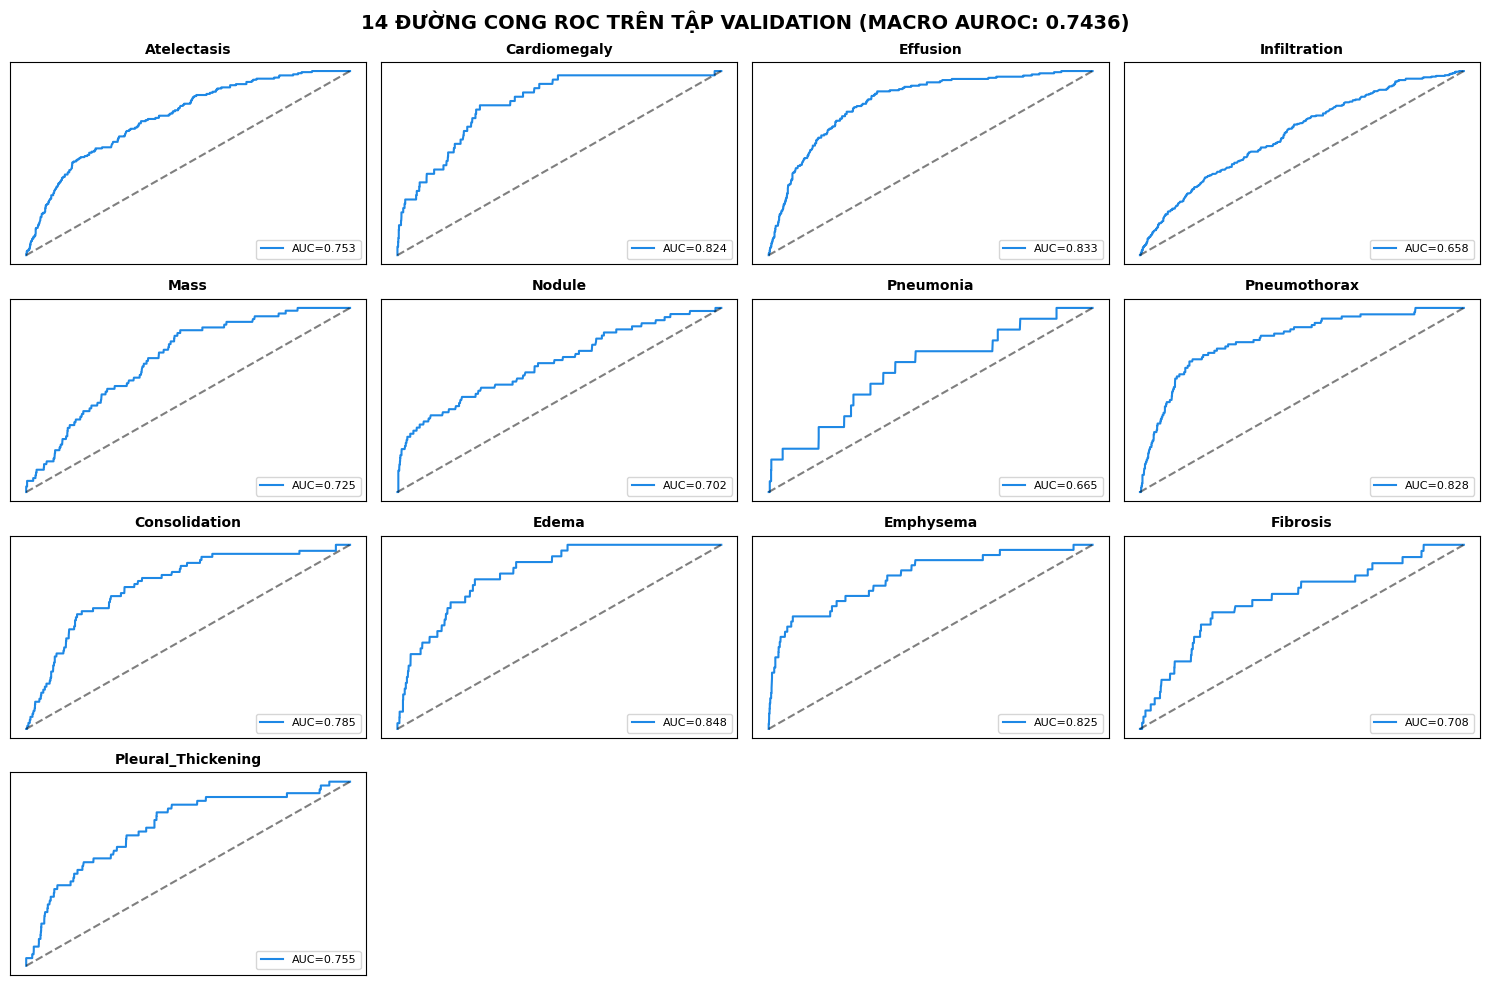

In [7]:
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for imgs, lbls in val_loader:
        imgs = imgs.to(device)
        with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
            preds = torch.sigmoid(model(imgs))
        all_preds.append(preds.cpu().numpy())
        all_targets.append(lbls.numpy())

all_preds = np.vstack(all_preds)
all_targets = np.vstack(all_targets)

auroc_records = []
plt.figure(figsize=(15, 10))

for i, c in enumerate(NIH_14_CLASSES):
    # Kiem tra xem tap val co du 2 lop khong
    if len(np.unique(all_targets[:, i])) > 1:
        score = roc_auc_score(all_targets[:, i], all_preds[:, i])
        fpr, tpr, _ = roc_curve(all_targets[:, i], all_preds[:, i])
        auroc_records.append({'Pathology': c, 'AUROC': score})
        
        # Plot ROC curve
        plt.subplot(4, 4, i + 1)
        plt.plot(fpr, tpr, color='#1E88E5', label=f'AUC={score:.3f}')
        plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
        plt.title(c, fontsize=10, fontweight='bold')
        plt.legend(loc='lower right', fontsize=8)
        plt.xticks([])
        plt.yticks([])
    else:
        auroc_records.append({'Pathology': c, 'AUROC': 0.5})

df_auroc = pd.DataFrame(auroc_records)
macro_auc = df_auroc['AUROC'].mean()
print(f'=== BẢNG CHỈ SỐ AUROC 14 BỆNH NIH (MACRO AUROC: {macro_auc:.4f}) ===')
print(df_auroc.to_string(index=False))

plt.suptitle(f'14 ĐƯỜNG CONG ROC TRÊN TẬP VALIDATION (MACRO AUROC: {macro_auc:.4f})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'nih_val_roc_curves.png'), dpi=150)
plt.show()


### 7. Kết Luận Khả Thi & Bàn Giao Cho Phase 3 Multi-Task
Xuất bảng số liệu đo đạc thực nghiệm ra file CSV và lưu checkpoint trọng số mô hình tốt nhất.


In [8]:
metrics_csv = os.path.join(output_dir, 'nih_baseline_metrics.csv')
df_auroc.to_csv(metrics_csv, index=False)

ckpt_file = os.path.join(ckpt_dir, 'nih_single_task_baseline.pth')
torch.save({
    'model_state_dict': model.state_dict(),
    'macro_auc': macro_auc,
    'classes': NIH_14_CLASSES,
    'pos_weights': df_classes['pos_weight'].tolist()
}, ckpt_file)

print(f'[XUẤT BẢN THÀNH CÔNG] Bảng chỉ số AUROC đã lưu tại: {metrics_csv}')
print(f'[XUẤT BẢN THÀNH CÔNG] Trọng số mô hình đã lưu tại: {ckpt_file}')
print('\n>>> HEAD A (NIH CHESTX-RAY14) HOÀN TOÀN ĐẠT CHUẨN ĐỂ GHÉP VÀO MULTI-TASK 3-HEAD! <<<')


[XUẤT BẢN THÀNH CÔNG] Bảng chỉ số AUROC đã lưu tại: /kaggle/working/results/nih/nih_baseline_metrics.csv
[XUẤT BẢN THÀNH CÔNG] Trọng số mô hình đã lưu tại: /kaggle/working/checkpoints/nih_single_task_baseline.pth

>>> HEAD A (NIH CHESTX-RAY14) HOÀN TOÀN ĐẠT CHUẨN ĐỂ GHÉP VÀO MULTI-TASK 3-HEAD! <<<
